In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math

df = pd.read_csv("../../datasets/heart.csv")

numerical_columns = df.select_dtypes(include="number").columns.tolist()

print("Dataset shape:", df.shape)
print("Numerical columns:", numerical_columns)

Dataset shape: (1025, 14)
Numerical columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [2]:
def manual_correlation(x_values, y_values):
    pairs = [
        (float(x), float(y))
        for x, y in zip(x_values, y_values)
        if pd.notna(x) and pd.notna(y)
    ]

    if len(pairs) < 2:
        return 0

    x = [pair[0] for pair in pairs]
    y = [pair[1] for pair in pairs]

    mean_x = sum(x) / len(x)
    mean_y = sum(y) / len(y)

    numerator = sum(
        (x[i] - mean_x) * (y[i] - mean_y)
        for i in range(len(x))
    )

    sum_x_squared = sum((value - mean_x) ** 2 for value in x)
    sum_y_squared = sum((value - mean_y) ** 2 for value in y)

    denominator = math.sqrt(sum_x_squared * sum_y_squared)

    if denominator == 0:
        return 0

    return numerator / denominator

In [3]:
correlation_threshold = 0.5
correlation_results = []

for i in range(len(numerical_columns)):
    for j in range(i + 1, len(numerical_columns)):
        col_x = numerical_columns[i]
        col_y = numerical_columns[j]

        correlation = manual_correlation(df[col_x], df[col_y])

        correlation_results.append(
            (col_x, col_y, correlation)
        )

        print(f"{col_x} vs {col_y}: {correlation:.3f}")

selected_pairs = [
    (col_x, col_y, correlation)
    for col_x, col_y, correlation in correlation_results
    if abs(correlation) >= correlation_threshold
]

print("\nHighly correlated pairs:")
for col_x, col_y, correlation in selected_pairs:
    print(f"{col_x} vs {col_y}: r = {correlation:.3f}")

if not selected_pairs:
    print("No pairs met the selected correlation threshold.")

age vs sex: -0.103
age vs cp: -0.072
age vs trestbps: 0.271
age vs chol: 0.220
age vs fbs: 0.121
age vs restecg: -0.133
age vs thalach: -0.390
age vs exang: 0.088
age vs oldpeak: 0.208
age vs slope: -0.169
age vs ca: 0.272
age vs thal: 0.072
age vs target: -0.229
sex vs cp: -0.041
sex vs trestbps: -0.079
sex vs chol: -0.198
sex vs fbs: 0.027
sex vs restecg: -0.055
sex vs thalach: -0.049
sex vs exang: 0.139
sex vs oldpeak: 0.085
sex vs slope: -0.027
sex vs ca: 0.112
sex vs thal: 0.198
sex vs target: -0.280
cp vs trestbps: 0.038
cp vs chol: -0.082
cp vs fbs: 0.079
cp vs restecg: 0.044
cp vs thalach: 0.307
cp vs exang: -0.402
cp vs oldpeak: -0.175
cp vs slope: 0.132
cp vs ca: -0.176
cp vs thal: -0.163
cp vs target: 0.435
trestbps vs chol: 0.128
trestbps vs fbs: 0.182
trestbps vs restecg: -0.124
trestbps vs thalach: -0.039
trestbps vs exang: 0.061
trestbps vs oldpeak: 0.187
trestbps vs slope: -0.120
trestbps vs ca: 0.105
trestbps vs thal: 0.059
trestbps vs target: -0.139
chol vs fbs: 0.027

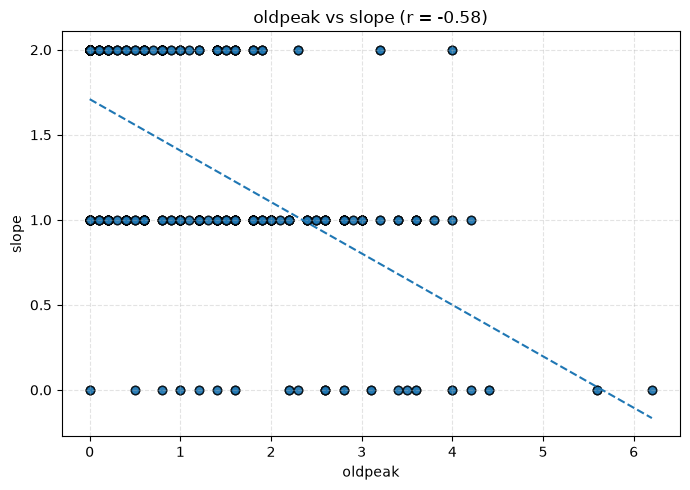

In [4]:
for col_x, col_y, correlation in selected_pairs:
    pairs = [
        (float(x), float(y))
        for x, y in zip(df[col_x], df[col_y])
        if pd.notna(x) and pd.notna(y)
    ]

    if len(pairs) < 2:
        continue

    x = [pair[0] for pair in pairs]
    y = [pair[1] for pair in pairs]

    mean_x = sum(x) / len(x)
    mean_y = sum(y) / len(y)

    denominator = sum((value - mean_x) ** 2 for value in x)

    if denominator == 0:
        continue

    slope = sum(
        (x[i] - mean_x) * (y[i] - mean_y)
        for i in range(len(x))
    ) / denominator

    intercept = mean_y - slope * mean_x

    line_x = [min(x), max(x)]
    line_y = [slope * value + intercept for value in line_x]

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(x, y, alpha=0.6, edgecolors="black")
    ax.plot(line_x, line_y, linestyle="--")

    ax.set_title(
        f"{col_x} vs {col_y} (r = {correlation:.2f})"
    )
    ax.set_xlabel(col_x)
    ax.set_ylabel(col_y)
    ax.grid(True, linestyle="--", alpha=0.35)

    plt.tight_layout()
    plt.show()

In [5]:
ranked_pairs = sorted(
    correlation_results,
    key=lambda item: abs(item[2]),
    reverse=True
)

print("Feature pairs ranked by absolute correlation:\n")

for col_x, col_y, correlation in ranked_pairs:
    print(f"{col_x} vs {col_y}: r = {correlation:.3f}")

Feature pairs ranked by absolute correlation:

oldpeak vs slope: r = -0.575
oldpeak vs target: r = -0.438
exang vs target: r = -0.438
cp vs target: r = 0.435
thalach vs target: r = 0.423
cp vs exang: r = -0.402
thalach vs slope: r = 0.395
age vs thalach: r = -0.390
ca vs target: r = -0.382
thalach vs exang: r = -0.380
thalach vs oldpeak: r = -0.350
slope vs target: r = 0.346
thal vs target: r = -0.338
exang vs oldpeak: r = 0.311
cp vs thalach: r = 0.307
sex vs target: r = -0.280
age vs ca: r = 0.272
age vs trestbps: r = 0.271
exang vs slope: r = -0.267
age vs target: r = -0.229
oldpeak vs ca: r = 0.222
age vs chol: r = 0.220
age vs oldpeak: r = 0.208
thalach vs ca: r = -0.208
oldpeak vs thal: r = 0.203
sex vs thal: r = 0.198
sex vs chol: r = -0.198
exang vs thal: r = 0.197
trestbps vs oldpeak: r = 0.187
trestbps vs fbs: r = 0.182
cp vs ca: r = -0.176
cp vs oldpeak: r = -0.175
age vs slope: r = -0.169
cp vs thal: r = -0.163
ca vs thal: r = 0.149
chol vs restecg: r = -0.147
sex vs exang:

# Task 15: Manual Pair Plots and Correlation Analysis

## Objective
To manually calculate correlation coefficients, dynamically select highly correlated numerical feature pairs, and visualize relationships using scatter plots with manually calculated trendlines.

## Methodology
1. Loaded the Heart Disease dataset and selected numerical columns.
2. Implemented Pearson correlation calculation using arithmetic operations.
3. Calculated correlations for every pair of numerical features.
4. Selected pairs whose absolute correlation met the chosen threshold.
5. Calculated linear trendline slopes and intercepts manually.
6. Visualized selected pairs using Matplotlib scatter and line plotting commands.
7. Ranked feature pairs by absolute correlation strength.

## Conclusion
Manual correlation calculations were used to identify potentially related numerical features. Scatter plots and trendlines help visualize the direction and strength of linear relationships. Correlation does not establish causation, and encoded categorical variables should be interpreted carefully.

The selected pairs and their correlation coefficients should be reported based on the notebook outputs.
